# Sprint 09 · Equipo 5 Green
## Reto «Conocer al huésped» — TurisData

Fecha : 16 - 17.11.2026

**Integrantes:** Cristina, Miguel, Fran, Andri y Anzhela.

Scrum master Cristina, Tecnico Francis

**Pregunta del cliente:** ¿qué tipos de huésped tenemos y qué experiencias podemos ofrecerles?

Ejecutad las celdas **de arriba abajo**. Los datos se descargan desde el repositorio del curso; no hace falta subir los CSV.

Este cuaderno:
1. Escala las 7 variables numéricas de los 1.200 huéspedes.
2. Compara k-means para k de 2 a 8 con el coeficiente de silueta.
3. Crea un mapa PCA 2D con el porcentaje de varianza de cada eje y guarda `mapa_pca.png`.
4. Resume segmentos con tamaño, porcentaje, perfil y acciones orientativas.
5. Compara popularidad e item-item con valoraciones de prueba ocultas, RMSE y precision@3.
6. Incluye `recomendar(id_usuario, n)` y comprueba que no repite experiencias ya valoradas.

**Límite importante:** los materiales muestran 1.200 huéspedes y 300 usuarios del recomendador, pero no documentan una clave para relacionar ambos ficheros. No inventamos esa unión; las recomendaciones por segmento quedan pendientes de validar con una correspondencia real.

**Reproducibilidad:** semilla fija 42. En Colab, usad **Entorno de ejecución → Reiniciar sesión y ejecutar todo**.


## 1. Preparación de datos y herramientas
Ejecuta esta celda primero. Descarga los tres archivos oficiales del sprint.

In [1]:
import os, urllib.request
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.metrics.pairwise import cosine_similarity

SEMILLA = 42
np.random.seed(SEMILLA)
sns.set_theme(style="whitegrid")
BASE_URL = "https://raw.githubusercontent.com/cCoolBoox/IFCD107-alumnado/main/datos/"
Path("datos").mkdir(exist_ok=True)

def descargar_dato(nombre):
    ruta = Path("datos") / nombre
    if not ruta.exists():
        try:
            urllib.request.urlretrieve(BASE_URL + nombre, ruta)
        except Exception as e:
            raise RuntimeError(f"No se pudo descargar {nombre}. Comprueba la conexión de Colab.") from e
    return ruta

huespedes = pd.read_csv(descargar_dato("huespedes.csv"))
valoraciones = pd.read_csv(descargar_dato("valoraciones_experiencias.csv"))
experiencias = pd.read_csv(descargar_dato("experiencias.csv"))
print("Huéspedes:", huespedes.shape, "| Valoraciones:", valoraciones.shape, "| Experiencias:", experiencias.shape)
print("Listo ✔")


Huéspedes: (1200, 8) | Valoraciones: (2232, 3) | Experiencias: (25, 4)
Listo ✔


## 2. Conocer y preparar a los huéspedes
Cada fila es un huésped. `id_huesped` identifica la fila, pero no describe su comportamiento y no se usa para agrupar.

In [2]:
display(huespedes.head())
display(huespedes.describe().T.round(2))

variables = [c for c in huespedes.select_dtypes(include=np.number).columns if c != "id_huesped"]
if len(variables) != 7:
    raise ValueError(f"Se esperaban 7 variables numéricas de comportamiento; se encontraron {len(variables)}: {variables}")
X_original = huespedes[variables].copy()
if X_original.isna().any().any():
    X_original = X_original.fillna(X_original.median(numeric_only=True))
escalador = StandardScaler()
X = escalador.fit_transform(X_original)
print("Variables:", variables)
print("Dimensiones de X:", X.shape)
print("Medias:", np.round(X.mean(axis=0), 3))
print("Desviaciones:", np.round(X.std(axis=0), 3))
assert X.shape == (1200, 7)
print("✔ Variables escaladas antes de agrupar")


,id_huesped,edad,gasto_medio_dia,noches_medias,reservas_anio,antelacion_media,pct_gasto_actividades,viaja_con_ninos
0,1,26,92.25,3.9,4,24,40.2,0
1,2,41,92.81,5.3,2,115,17.6,1
2,3,60,200.24,6.4,1,126,39.0,0
3,4,38,74.47,5.5,0,58,86.7,0
4,5,54,266.46,6.9,1,116,11.7,0


,count,mean,std,min,25%,50%,75%,max
id_huesped,1200.0,600.50,346.55,1.00,300.75,600.5,900.25,1200.00
edad,1200.0,41.21,12.11,18.00,33.00,39.0,50.00,75.00
gasto_medio_dia,1200.0,124.22,60.88,34.58,79.56,101.8,155.12,338.71
noches_medias,1200.0,6.52,2.25,1.00,5.40,6.9,8.10,11.50
reservas_anio,1200.0,1.98,1.68,0.00,1.00,2.0,3.00,10.00
antelacion_media,1200.0,78.65,36.51,0.00,53.00,83.0,106.00,180.00
pct_gasto_actividades,1200.0,38.51,23.72,0.00,20.90,31.7,53.25,100.00
viaja_con_ninos,1200.0,0.33,0.47,0.00,0.00,0.0,1.00,1.00


Variables: ['edad', 'gasto_medio_dia', 'noches_medias', 'reservas_anio', 'antelacion_media', 'pct_gasto_actividades', 'viaja_con_ninos']
Dimensiones de X: (1200, 7)
Medias: [ 0. -0.  0. -0. -0.  0.  0.]
Desviaciones: [1. 1. 1. 1. 1. 1. 1.]
✔ Variables escaladas antes de agrupar


## 3. Elegir k con k-means y silueta
Probamos k de 2 a 8. La silueta ayuda a medir separación y cohesión; también debemos elegir un número de grupos que Lucía pueda gestionar.

,k,silueta
0,2,0.3671
1,3,0.4148
2,4,0.4313
3,5,0.4139
4,6,0.3256
5,7,0.3175
6,8,0.2569


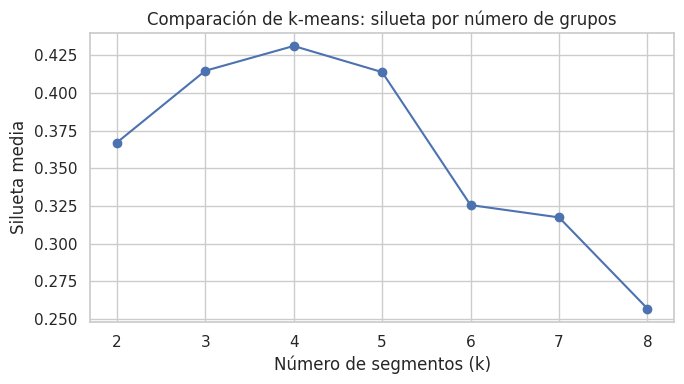

k con mayor silueta: 4


In [3]:
siluetas, modelos_kmeans = {}, {}
for k in range(2, 9):
    modelo = KMeans(n_clusters=k, n_init=10, random_state=SEMILLA)
    etiquetas = modelo.fit_predict(X)
    modelos_kmeans[k] = modelo
    siluetas[k] = silhouette_score(X, etiquetas)
tabla_silueta = pd.DataFrame({"k": list(siluetas), "silueta": list(siluetas.values())})
display(tabla_silueta.round(4))
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(tabla_silueta["k"], tabla_silueta["silueta"], marker="o")
ax.set(xlabel="Número de segmentos (k)", ylabel="Silueta media",
       title="Comparación de k-means: silueta por número de grupos")
plt.tight_layout()
plt.show()
k_mejor_silueta = max(siluetas, key=siluetas.get)
print("k con mayor silueta:", k_mejor_silueta)


### Decisión del equipo sobre k
Por defecto usamos el k con mayor silueta. Si la curva tiene valores parecidos, el equipo puede escoger un k cercano más fácil de gestionar, explicando por qué. Cambiad `K_ELEGIDO` solo si podéis justificarlo con la curva y con el negocio.

In [4]:
K_ELEGIDO = k_mejor_silueta  # Cambiar solo si justificáis otra opción entre 2 y 8.
if K_ELEGIDO not in range(2, 9):
    raise ValueError("K_ELEGIDO debe estar entre 2 y 8.")
modelo_final = KMeans(n_clusters=K_ELEGIDO, n_init=10, random_state=SEMILLA)
grupo = modelo_final.fit_predict(X)
huespedes_segmentados = huespedes.copy()
huespedes_segmentados["grupo"] = grupo
conteos = huespedes_segmentados["grupo"].value_counts().sort_index()
resumen_tamanos = pd.DataFrame({
    "n": conteos,
    "porcentaje": (conteos / len(huespedes_segmentados) * 100).round(1)
})
display(resumen_tamanos)
print(f"Justificación: elegimos k={K_ELEGIDO}; silueta={siluetas[K_ELEGIDO]:.3f}. "
      "El número de grupos debe permitir campañas diferenciadas sin complicar su gestión.")


,n,porcentaje
grupo,,
0,194,16.2
1,402,33.5
2,317,26.4
3,287,23.9


Justificación: elegimos k=4; silueta=0.431. El número de grupos debe permitir campañas diferenciadas sin complicar su gestión.


## 4. Interpretar los segmentos
La tabla calcula tamaño y medias. Revisad los perfiles y redactad nombres comerciales y acciones usando las cifras reales.

In [5]:
perfil = huespedes_segmentados.groupby("grupo")[variables].mean().round(2)
perfil.insert(0, "n", conteos)
perfil.insert(1, "porcentaje", (conteos / len(huespedes_segmentados) * 100).round(1))
display(perfil)
variable_gasto = "gasto_medio_dia" if "gasto_medio_dia" in variables else variables[0]
orden = perfil[variable_gasto].sort_values().index.tolist()
nombres = {}
for pos, g in enumerate(orden):
    nivel = "Gasto más bajo" if pos == 0 else ("Gasto más alto" if pos == len(orden)-1 else f"Gasto nivel {pos+1}")
    nombres[g] = f"Segmento {g+1} · {nivel}"
acciones = {}
for g in perfil.index:
    gasto = perfil.loc[g, variable_gasto]
    if gasto == perfil[variable_gasto].max():
        acciones[g] = "Probar ofertas premium y experiencias exclusivas; medir conversión."
    elif gasto == perfil[variable_gasto].min():
        acciones[g] = "Probar paquetes asequibles y promociones claras; evitar presión comercial."
    else:
        acciones[g] = "Probar una selección equilibrada de experiencias y comparar clics y reservas."
ficha_segmentos_auto = perfil.copy()
ficha_segmentos_auto.insert(0, "nombre_orientativo", pd.Series(nombres))
ficha_segmentos_auto["accion_orientativa"] = pd.Series(acciones)
display(ficha_segmentos_auto)


,n,porcentaje,edad,gasto_medio_dia,noches_medias,reservas_anio,antelacion_media,pct_gasto_actividades,viaja_con_ninos
grupo,,,,,,,,,
0,194,16.2,34.61,120.37,2.65,4.02,22.24,41.25,0.06
1,402,33.5,40.32,95.19,7.44,1.27,110.27,26.00,0.91
2,317,26.4,57.17,211.37,8.08,1.57,90.26,20.02,0.02
3,287,23.9,29.27,71.22,6.14,2.06,59.69,74.60,0.05


,nombre_orientativo,n,porcentaje,edad,gasto_medio_dia,noches_medias,reservas_anio,antelacion_media,pct_gasto_actividades,viaja_con_ninos,accion_orientativa
grupo,,,,,,,,,,,
0,Segmento 1 · Gasto nivel 3,194,16.2,34.61,120.37,2.65,4.02,22.24,41.25,0.06,Probar una selección equilibrada de experienci...
1,Segmento 2 · Gasto nivel 2,402,33.5,40.32,95.19,7.44,1.27,110.27,26.00,0.91,Probar una selección equilibrada de experienci...
2,Segmento 3 · Gasto más alto,317,26.4,57.17,211.37,8.08,1.57,90.26,20.02,0.02,Probar ofertas premium y experiencias exclusiv...
3,Segmento 4 · Gasto más bajo,287,23.9,29.27,71.22,6.14,2.06,59.69,74.60,0.05,Probar paquetes asequibles y promociones clara...


## 5. Mapa 2D con PCA
PCA resume las 7 variables en dos componentes. Los porcentajes muestran cuánta variación conserva cada eje; el mapa sirve para visualizar, no sustituye el análisis completo.

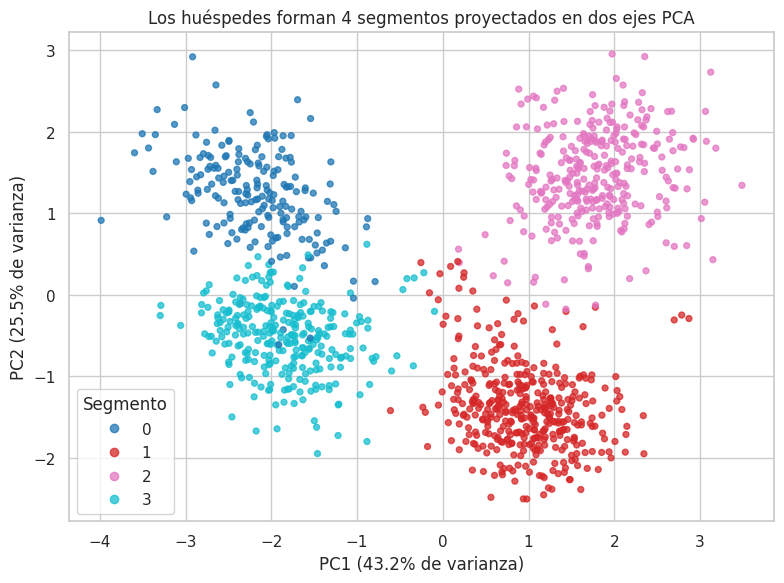

PC1: 43.2% | PC2: 25.5% | Total 2D: 68.7%


,PC1,PC2
edad,0.447,0.367
gasto_medio_dia,0.332,0.554
noches_medias,0.421,-0.159
reservas_anio,-0.290,0.304
antelacion_media,0.437,-0.338
pct_gasto_actividades,-0.445,-0.145
viaja_con_ninos,0.199,-0.553


In [6]:
pca_2d = PCA(n_components=2, random_state=SEMILLA)
Z2 = pca_2d.fit_transform(X)
var_pc1, var_pc2 = pca_2d.explained_variance_ratio_ * 100
fig, ax = plt.subplots(figsize=(8, 6))
puntos = ax.scatter(Z2[:, 0], Z2[:, 1], c=grupo, cmap="tab10", s=18, alpha=0.75)
ax.set_xlabel(f"PC1 ({var_pc1:.1f}% de varianza)")
ax.set_ylabel(f"PC2 ({var_pc2:.1f}% de varianza)")
ax.set_title(f"Los huéspedes forman {K_ELEGIDO} segmentos proyectados en dos ejes PCA")
ax.legend(*puntos.legend_elements(), title="Segmento")
plt.tight_layout()
plt.savefig("mapa_pca.png", dpi=180, bbox_inches="tight")
plt.show()
print(f"PC1: {var_pc1:.1f}% | PC2: {var_pc2:.1f}% | Total 2D: {var_pc1+var_pc2:.1f}%")
cargas = pd.DataFrame(pca_2d.components_.T, index=variables, columns=["PC1", "PC2"]).round(3)
display(cargas)


## 6. Recomendador: popularidad e item-item
Separamos un 20% de las valoraciones como prueba. Esas notas ocultas no se usan para entrenar.

In [7]:
usuarios = sorted(valoraciones["id_usuario"].unique())
items = sorted(experiencias["id_experiencia"].unique())
prueba = valoraciones.sample(frac=0.20, random_state=SEMILLA)
entrenamiento = valoraciones.drop(prueba.index)
R = entrenamiento.pivot(index="id_usuario", columns="id_experiencia", values="valoracion").reindex(index=usuarios, columns=items)
M_visto = R.notna().values
media_global = float(entrenamiento["valoracion"].mean())
medias_item = R.mean(axis=0).fillna(media_global)
P_pop = np.tile(medias_item.reindex(items).values, (len(usuarios), 1))
media_item = medias_item.reindex(items).values
Rv = R.values.astype(float)
mascara = np.isfinite(Rv)
C_residuos = np.where(mascara, Rv - media_item[None, :], 0.0)
S = cosine_similarity(C_residuos.T)
np.fill_diagonal(S, 0.0)
numerador = C_residuos @ S.T
denominador = M_visto.astype(float) @ np.abs(S).T
P_item = media_item[None, :] + numerador / (denominador + 1e-9)

map_u = {u:i for i,u in enumerate(usuarios)}
map_i = {it:i for i,it in enumerate(items)}
fila_p = prueba["id_usuario"].map(map_u).values
col_p = prueba["id_experiencia"].map(map_i).values
real_p = prueba["valoracion"].astype(float).values

def evaluar_rmse(P):
    pred = np.clip(P[fila_p, col_p], 1, 5)
    return float(np.sqrt(np.mean((pred-real_p)**2)))

def precision_k(P, k=3):
    positivos = prueba[prueba["valoracion"] >= 4]
    relevantes = positivos.groupby("id_usuario")["id_experiencia"].apply(set)
    valores = []
    for u, relevantes_u in relevantes.items():
        i = map_u[u]
        scores = P[i].copy()
        scores[M_visto[i]] = -np.inf
        top = {items[j] for j in np.argsort(-scores)[:k] if np.isfinite(scores[j])}
        valores.append(len(top & relevantes_u) / k)
    return float(np.mean(valores)) if valores else 0.0

tabla_metricas = pd.DataFrame({
    "RMSE": [evaluar_rmse(P_pop), evaluar_rmse(P_item)],
    "precision@3": [precision_k(P_pop, 3), precision_k(P_item, 3)]
}, index=["Popularidad", "Item-item"])
display(tabla_metricas.round(4))
print("Menor RMSE:", tabla_metricas["RMSE"].idxmin())
print("Mayor precision@3:", tabla_metricas["precision@3"].idxmax())


,RMSE,precision@3
Popularidad,1.0287,0.1246
Item-item,0.8954,0.1710


Menor RMSE: Item-item
Mayor precision@3: Item-item


## 7. Función recomendar(id_usuario, n)
Devuelve las mejores experiencias que el usuario aún no ha valorado. La matriz por defecto es item-item; podéis pasar `P=P_pop` para probar popularidad.

In [8]:
catalogo = experiencias.set_index("id_experiencia")
def recomendar(id_usuario, n=3, P=P_item):
    if id_usuario not in map_u:
        raise ValueError(f"El usuario {id_usuario} no existe en el histórico.")
    i = map_u[id_usuario]
    puntuaciones = P[i].copy()
    puntuaciones[M_visto[i]] = -np.inf
    mejores = [j for j in np.argsort(-puntuaciones) if np.isfinite(puntuaciones[j])][:n]
    ids = [items[j] for j in mejores]
    salida = catalogo.loc[ids].copy()
    salida["puntuacion_prevista"] = [float(np.clip(puntuaciones[j], 1, 5)) for j in mejores]
    salida.index.name = "id_experiencia"
    return salida.reset_index()

for u in usuarios[:3]:
    print("Recomendaciones para usuario", u)
    resultado = recomendar(u, n=3)
    display(resultado)
    ya_valoradas = set(entrenamiento.loc[entrenamiento.id_usuario == u, "id_experiencia"])
    assert ya_valoradas.isdisjoint(set(resultado["id_experiencia"]))
print("✔ No se repiten experiencias ya valoradas en tres usuarios.")


Recomendaciones para usuario 1


,id_experiencia,nombre,categoria,isla,puntuacion_prevista
0,11,Parque Timanfaya,naturaleza,Lanzarote,4.727141
1,3,Ruta por Anaga,naturaleza,Tenerife,4.140728
2,20,Zoo y jardines,familia,Gran Canaria,3.873268


Recomendaciones para usuario 2


,id_experiencia,nombre,categoria,isla,puntuacion_prevista
0,2,Observación de cetáceos,mar,Tenerife,4.548885
1,13,Astronomía en el Roque,cultura,La Palma,4.505059
2,24,Parapente,aventura,Tenerife,3.899092


Recomendaciones para usuario 3


,id_experiencia,nombre,categoria,isla,puntuacion_prevista
0,22,Visita a Garachico,cultura,Tenerife,5.000000
1,15,Ruta del queso majorero,gastronomia,Fuerteventura,4.165021
2,3,Ruta por Anaga,naturaleza,Tenerife,3.986944


✔ No se repiten experiencias ya valoradas en tres usuarios.


## 8. Experiencia destacada y límite de los datos
Mostramos la experiencia con mayor media de valoración como referencia global. No la atribuimos a cada segmento: no hay una clave documentada que una `id_huesped` con `id_usuario`. Para personalizar por segmento, TurisData debe facilitar una correspondencia autorizada.

In [9]:
id_estrella = int(medias_item.idxmax())
display(experiencias.set_index("id_experiencia").loc[[id_estrella]])
print("Experiencia global de referencia:", id_estrella)
print("Pendiente: correspondencia huésped-usuario para recomendaciones segmentadas fiables.")


,nombre,categoria,isla
id_experiencia,,,
11,Parque Timanfaya,naturaleza,Lanzarote


Experiencia global de referencia: 11
Pendiente: correspondencia huésped-usuario para recomendaciones segmentadas fiables.


## 9. Extra opcional: clustering jerárquico y DBSCAN
Comparamos jerárquico con el mismo número de grupos. DBSCAN puede detectar ruido y producir un número distinto de grupos.

In [10]:
jerarquico = AgglomerativeClustering(n_clusters=K_ELEGIDO, linkage="ward")
grupo_jerarquico = jerarquico.fit_predict(X)
dbscan = DBSCAN(eps=1.2, min_samples=10).fit_predict(X)
n_dbscan = len(set(dbscan) - {-1})
sil_dbscan = silhouette_score(X, dbscan) if 1 < n_dbscan < len(X) else np.nan
comparacion = pd.DataFrame({
    "Algoritmo": ["K-means", "Jerárquico Ward", "DBSCAN"],
    "Grupos": [K_ELEGIDO, len(set(grupo_jerarquico)), n_dbscan],
    "Silueta": [silhouette_score(X, grupo), silhouette_score(X, grupo_jerarquico), sil_dbscan],
    "Puntos de ruido": [0, 0, int(np.sum(dbscan == -1))]
})
display(comparacion.round(4))


,Algoritmo,Grupos,Silueta,Puntos de ruido
0,K-means,4,0.4313,0
1,Jerárquico Ward,4,0.4239,0
2,DBSCAN,3,0.3924,46


## 10. Uso responsable de IA y declaración del equipo

Completad y revisad esta nota antes de entregar:

- **Dónde usamos IA:** para entender errores, revisar la estructura del notebook y redactar explicaciones iniciales.
- **Qué comprobamos a mano:** descarga de los CSV, exclusión del identificador, escalado de las siete variables, tamaños de segmentos y métricas.
- **Riesgo 1 — sesgo de popularidad:** unas pocas experiencias pueden dominar. Medida: comparar métodos y revisar diversidad.
- **Riesgo 2 — discriminación:** edad o viajar con niños podrían generar ofertas desiguales. Medida: no excluir ofertas por esas variables y revisar resultados por grupos.
- **Riesgo 3 — privacidad:** hábitos de viaje pueden ser sensibles. Medida: usar identificadores seudónimos y limitar accesos.
- **Límite:** los datos son sintéticos y falta la correspondencia huésped-usuario.

## 11. Checklist de entrega

- [x] Reiniciar y ejecutar todo sin errores.
- [x] Siete variables escaladas antes de agrupar.
- [x] k de 2 a 8 comparados y k justificado por silueta y negocio.
- [x] PCA con porcentaje de varianza en cada eje; se genera `mapa_pca.png`.
- [x] Ficha con nombre, tamaño, porcentaje, perfil con cifras y acción por segmento.
- [x] Los tamaños suman 1.200.
- [x] Popularidad e item-item evaluados con RMSE y precision@3 sobre valoraciones ocultas.
- [x] `recomendar` probado con tres usuarios y sin repetir experiencias valoradas.
- [x] Dos riesgos concretos de IA responsable con medidas.
- [x] Cada integrante hace su commit.
- [x] Una persona distinta revisa el trabajo con la rúbrica.

El notebook genera `mapa_pca.png` y `ficha_segmentos_auto`. Descargad el PNG desde el panel de archivos de Colab si lo vais a incluir en la ficha.
